## Data Preprocessing ##

In [1]:
import random
import pickle
import sklearn.metrics

import numpy as np
import matplotlib.pyplot as plt

from scipy.spatial import distance
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets

### Calculating mean and standard deviation of CIFAR 10 dataset ###

In [3]:
cifar_trainset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transforms.ToTensor())

imgs = [item[0] for item in cifar_trainset]
imgs = torch.stack(imgs, dim=0).numpy()
imgs = imgs.transpose(1,0,2,3)
imgs = imgs.reshape([imgs.shape[0],imgs.shape[1]*imgs.shape[2]*imgs.shape[3]])

mean = imgs.mean(axis = 1)
print(mean)

std = imgs.std(axis = 1)
print(std)

 24%|██▍       | 41.2M/170M [00:19<01:01, 2.10MB/s]


KeyboardInterrupt: 

## Reading 10% of the train and validation dataset with mean and std normalization ##

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    # transforms.RandomHorizontalFlip(),
    # transforms.RandomRotation(10),
    transforms.Normalize(mean, std),
    # transforms.Grayscale(),
    torch.flatten
])

train_size = 5000
test_size = 1000
train_dataset =  datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
validation_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, shuffle=True, batch_size=train_size, num_workers=2)
validation_loader = torch.utils.data.DataLoader(dataset=validation_dataset, shuffle=True, batch_size=int(test_size), num_workers=2)

Files already downloaded and verified
Files already downloaded and verified


In [628]:
images_train, labels_train = next(iter(train_loader))
images_val, labels_val = next(iter(validation_loader))

In [629]:
images_train = np.transpose(images_train, [0,2,3,1])
images_val = np.transpose(images_val, [0,2,3,1])
labels_train = labels_train.numpy()
labels = labels_val.numpy()

X_train = np.reshape(images_train, (images_train.shape[0], -1)).numpy()
X_test = np.reshape(images_val, (images_val.shape[0], -1)).numpy()

### Reading the whole train and validation dataset with mean and std normalization ###

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    # transforms.RandomHorizontalFlip(),
    # transforms.RandomRotation(10),
    transforms.Normalize(mean, std),
    # transforms.Grayscale(),
    torch.flatten
])

train_size = 50000
test_size = 10000
train_dataset =  datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
validation_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, shuffle=True, batch_size=train_size, num_workers=2)
validation_loader = torch.utils.data.DataLoader(dataset=validation_dataset, shuffle=True, batch_size=int(test_size), num_workers=2)

NameError: name 'mean' is not defined

In [631]:
images_train_all, labels_train_all = next(iter(train_loader))
images_val_all, labels_val_all = next(iter(validation_loader))

images_train_all = np.transpose(images_train_all, [0,2,3,1])
images_val_all = np.transpose(images_val_all, [0,2,3,1])
labels_train_all = labels_train_all.numpy()
labels_all = labels_val_all.numpy()

X_train_all = np.reshape(images_train_all, (images_train_all.shape[0], -1)).numpy()
X_test_all = np.reshape(images_val_all, (images_val_all.shape[0], -1)).numpy()

## 1. My implementation of K-Nearest Neighbors Classifier ##

In [633]:
class KNN:
    def __init__(self, k=1):
        self.k = k

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
          
    def predict(self, X):
        predictions = [self._predict(x) for x in X]
        return predictions
    
    def _predict(self, x):
        distances = [distance.minkowski(x, x_train, p=2) for x_train in self.X_train]
        
        k_indices = np.argsort(distances)[:self.k] 
        
        k_nearest_labels = [int(self.y_train[i]) for i in k_indices]
        most_common = Counter(k_nearest_labels).most_common(self.k)[0]
        if most_common[1] == 1:
            prediction = k_nearest_labels[0]
        else:
            prediction = most_common[0]
        self.distances = [distances[i] for i in k_indices]
        self.kneighbors = k_nearest_labels
        return prediction

### 1.1 My k-Nearest Neighbors for k = 1 ###

In [634]:
classifier_1NN = KNN(k = 1)
classifier_1NN.fit(X_train, labels_train)
predictions_1NN = classifier_1NN.predict(X_test)

In [635]:
correct_1NN = np.sum(predictions_1NN == labels)
accuracy_1NN = float(correct_1NN) / len(labels)
print('Accuracy of my k-Nearest Neighbor k = 1 ',accuracy_1NN)

Accuracy of my k-Nearest Neighbor k = 1  0.26


### 1.2 Sklearn k-Nearest Neighbors for k = 1 ###

In [636]:
classifier_1NC = KNeighborsClassifier(n_neighbors=1, algorithm='brute')

classifier_1NC.fit(X_train, labels_train)
predictions_1NC = classifier_1NC.predict(X_test)
# distances_1NC, indices_1NC = classifier_1NC.kneighbors(X_test, n_neighbors=1, return_distance=True)
# kneighbors_1NC = [labels_train[i] for i in indices_1NC]
# predictions_1NC = [int(Counter(i).most_common(1)[0][0]) for i in kneighbors_1NC]

In [637]:
correct_1NC = np.sum(predictions_1NC == labels)
accuracy_1NC = float(correct_1NC) / len(labels)
print('Accuracy of sklearn KNeighborsClassifier k = 1 ', accuracy_1NC)

Accuracy of sklearn KNeighborsClassifier k = 1  0.26


In [638]:
s = sum(predictions_1NN[i] == predictions_1NC[i] for i in range(len(labels)))
print(s,'/', len(labels), ' matching predictions for KNN k = 1')

1000 / 1000  matching predictions for KNN k = 1


### 1.3 My k-Nearest Neighbors for k = 3 ###

In [639]:
classifier_3NN = KNN(k = 3)
classifier_3NN.fit(X_train, labels_train)
predictions_3NN = classifier_3NN.predict(X_test)
distances_3NN = classifier_3NN.distances
kneighbors_3NN = classifier_3NN.kneighbors

In [640]:
correct_3NN = np.sum(predictions_3NN == labels)
accuracy_3NN = float(correct_3NN) / len(labels)
print('Accuracy of my k-Nearest Neighbor k = 3 ',accuracy_3NN)

Accuracy of my k-Nearest Neighbor k = 3  0.292


### 1.4 Sklearn k-Nearest Neighbors for k = 3 ###

In [641]:
classifier_3NC = KNeighborsClassifier(n_neighbors=3, algorithm='brute')

classifier_3NC.fit(X_train, labels_train)
distances_3NC, indices_3NC = classifier_3NC.kneighbors(X_test, n_neighbors=3, return_distance=True)
kneighbors_3NC = [labels_train[i] for i in indices_3NC]
predictions_3NC = [int(Counter(i).most_common(3)[0][0]) for i in kneighbors_3NC]

In [642]:
correct_3NC = np.sum(predictions_3NC == labels)
accuracy_3NC = float(correct_3NC) / len(labels)
print('Accuracy of sklearn KNeighborsClassifier k = 3 ', accuracy_3NC)

Accuracy of sklearn KNeighborsClassifier k = 3  0.292


In [643]:
s = sum(predictions_3NN[i] == predictions_3NC[i] for i in range(len(labels)))
print(s,'/', len(labels), ' matching predictions for KNN k = 3')

1000 / 1000  matching predictions for KNN k = 3


### 1.5 Sklearn k-Nearest Neighbors for k = 1 on whole dataset###

In [644]:
classifier_1NC_all = KNeighborsClassifier(n_neighbors=1, algorithm='brute')

classifier_1NC_all.fit(X_train_all, labels_train_all)
distances_1NC_all, indices_1NC_all = classifier_1NC_all.kneighbors(X_test_all, n_neighbors=1, return_distance=True)
kneighbors_1NC_all = [labels_train_all[i] for i in indices_1NC_all]
predictions_1NC_all = [int(Counter(i).most_common(1)[0][0]) for i in kneighbors_1NC_all]

In [645]:
correct_1NC_all = np.sum(predictions_1NC_all == labels_all)
accuracy_1NC_all = float(correct_1NC_all) / len(labels_all)
print('Accuracy of sklearn KNeighborsClassifier k = 1 on whole dataset ', accuracy_1NC_all)

Accuracy of sklearn KNeighborsClassifier k = 1 on whole dataset  0.3541


### 1.6 Sklearn k-Nearest Neighbors for k = 3 on whole dataset ###

In [646]:
classifier_3NC_all = KNeighborsClassifier(n_neighbors=3, algorithm='brute')

classifier_3NC_all.fit(X_train_all, labels_train_all)
preds = classifier_3NC_all.predict(X_test_all)
distances_3NC_all, indices_3NC_all = classifier_3NC_all.kneighbors(X_test_all, n_neighbors=3, return_distance=True)
kneighbors_3NC_all = [labels_train_all[i] for i in indices_3NC_all]
predictions_3NC_all = [int(Counter(i).most_common(3)[0][0]) for i in kneighbors_3NC_all]

In [647]:
correct_3NC_all = np.sum(preds == labels_all)
accuracy_3NC_all = float(correct_3NC_all) / len(labels_all)
print('Accuracy of sklearn KNeighborsClassifier k = 3 on whole dataset ', accuracy_3NC_all)

Accuracy of sklearn KNeighborsClassifier k = 3 on whole dataset  0.3277


## 2. My implementation of Nearest Centroid Classifier ##

In [648]:
class MyNearestCentroid:
    def __init__(self):
        self.centroids = {}
        self.counts = {}

    def fit(self, X, y):
        X = X
        y = y
        
        for i in range(len(y)):
            label = y[i]
            if(label in self.centroids):
                self.centroids[label] = (self.centroids[label]*self.counts[label]+ X[i])/(self.counts[label]+1)
                # print(self.centroids[label])
                self.counts[label] += 1
            else:
                self.centroids[label] = X[i]
                self.counts[label] = 0

    def predict(self, X):
        self.centroids = dict(sorted(self.centroids.items()))
        self.counts = dict(sorted(self.counts.items()))
        predictions = np.array([self._predict(x) for x in X])
        args = predictions.copy()
        predictions = np.array([np.argsort(i) for i in predictions])
        args = [np.array(args[i])[predictions[i]] for i in range(len(predictions))]
        return predictions[:,0], predictions, args
    
    def _predict(self, x):
        x = x
       
        distances = [distance.minkowski(x, self.centroids[i], 2) for i in self.centroids]

        nearest = (distances)
        return nearest

### 2.1 My Nearest Centroid ###

In [649]:
classifier_MyNC = MyNearestCentroid()

classifier_MyNC.fit(X_train, labels_train)
predictions_MyNC, nearestCentroids, args = classifier_MyNC.predict(X_test)

In [650]:
correct_MyNC = np.sum(predictions_MyNC == labels)
accuracy_MyNC = float(correct_MyNC) / len(labels)
print('Accuracy of my Nearest Centroid ', accuracy_MyNC)

Accuracy of my Nearest Centroid  0.248


### 2.2 Sklearn Nearest Centroid ###

In [651]:
classifier_NC = NearestCentroid()

classifier_NC.fit(X_train, labels_train)
predictions_NC = classifier_NC.predict(X_test)

In [652]:
correct_NC = np.sum(predictions_NC == labels)
accuracy_NC = float(correct_NC) / len(labels_val)
print('Accuracy of sklearn Nearest Centroid ', accuracy_NC)

Accuracy of sklearn Nearest Centroid  0.248


In [653]:
s = sum(predictions_MyNC[i] == predictions_NC[i] for i in range(len(labels)))
print(s,'/', len(labels), ' matching predictions for NC')

995 / 1000  matching predictions for NC


### 2.3 Differences ###

In [654]:
for i in range(len(labels)):
    if nearestCentroids[i][0] != predictions_NC[i]:
        print('Nearest Centroids of test input with id: ', i,' and their distances')
        for j in range(len(nearestCentroids[i])):

            print('Class ', nearestCentroids[i][j], ' : ', args[i][j])
        print('Prediction of sklearn Nearest Centroid class', predictions_NC[i])
        print('')

Nearest Centroids of test input with id:  222  and their distances
Class  3  :  51.06389236450195
Class  2  :  51.103389739990234
Class  7  :  51.50101089477539
Class  0  :  51.58704376220703
Class  8  :  53.215667724609375
Class  1  :  53.22345733642578
Class  4  :  53.58481979370117
Class  5  :  54.00728988647461
Class  9  :  55.059085845947266
Class  6  :  57.0180549621582
Prediction of sklearn Nearest Centroid class 2

Nearest Centroids of test input with id:  223  and their distances
Class  4  :  39.051239013671875
Class  6  :  39.06499099731445
Class  3  :  41.17372512817383
Class  7  :  43.253173828125
Class  2  :  43.29499435424805
Class  5  :  44.66202163696289
Class  1  :  47.903968811035156
Class  9  :  55.09912109375
Class  8  :  58.437339782714844
Class  0  :  59.35837173461914
Prediction of sklearn Nearest Centroid class 6

Nearest Centroids of test input with id:  302  and their distances
Class  5  :  46.320499420166016
Class  2  :  46.33890151977539
Class  4  :  46.4417

### 2.4 Sklearn Nearest Centoid on whole dataset ###

In [655]:
classifier_NC_all = NearestCentroid()

classifier_NC_all.fit(X_train_all, labels_train_all)
predictions_NC_all = classifier_NC_all.predict(X_test_all)

In [657]:
correct_NC_all = np.sum(predictions_NC_all == labels_all)
accuracy_NC_all = float(correct_NC_all) / len(labels_val_all)
print('Accuracy of sklearn Nearest Centroid on whole dataset', accuracy_NC_all)

Accuracy of sklearn Nearest Centroid on whole dataset 0.277


## 3. My Neural Network ##

#### Loss Functions and Derivatives ####

In [4]:
def MSE(y_true, y_pred):
    return np.mean(np.power(y_true - y_pred, 2))

def MSEprime(y_true, y_pred):
    return 2 * (np.sum(y_pred - y_true)) / np.size(y_true)

def CE(y_true, y_pred):
    loss = np.zeros(len(y_pred))
    for i, y in enumerate(y_pred):
        loss[i] = -y_true[i][y] + np.log(np.sum(np.exp(y_true[i]))) 
    return np.mean(loss)

def CEprime(y_true, y_pred):
    grad = np.zeros(y_true.shape)
    # t = np.zeros(y_true.shape)
    # t[np.arange(y_pred.size), y_pred] = 1
    for i, y in enumerate(y_true):
        for j, p in enumerate(y):
            grad[i][j] = np.exp(p)/np.sum(np.exp(y)) - y_pred[i][j]
    return np.sum(grad, axis = 0)

#### Layer and Activation Layers templates ####

In [5]:
class Layer():
    def __init__(self):
        self.input = None
        self.output = None
        self.grad = None
        
    def forward(self, input):
        # TODO: return output
        pass

    def backward(self, gradient):
        # TODO: update parameters and return input gradient
        pass

class Activation(Layer):
    def __init__(self, activation, derivative):
        super().__init__()
        self.activation = activation
        self.derivative = derivative

    def forward(self, input):
        self.input = input
        return self.activation(self.input)

    def backward(self, gradient):
        return np.multiply(gradient, self.derivative(gradient))
    

#### ReLU, Sigmoid, Softmax Layers ####

In [6]:
class ReLU(Activation):
    def __init__(self):
        def reLU(input):
            return np.maximum(0,input)
        
        def derivative(gradient):
            return np.where(gradient > 0, 1, 0)
        
        super().__init__(reLU, derivative)

class Sigmoid(Activation):
    def __init__(self):
        def sigmoid(x):
            return 1 / (1 + np.exp(-x))

        def sigmoid_prime(x):
            s = sigmoid(x)
            return s * (1 - s)

        super().__init__(sigmoid, sigmoid_prime)

class Softmax(Layer):
    def forward(self, input):
        input = np.clip(input, None, 700)

        tmp = np.exp(np.array(input))
        self.output = tmp / np.sum(tmp)
        return np.reshape(self.output, input.shape)
    
    def backward(self, gradient):
        n = np.size(self.output)

        return np.matmul((np.identity(n) - self.output.T) * self.output, gradient)

#### Dense and Dropout Layer ####

In [7]:
class Dense(Layer):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.weights = np.random.randn(output_size, input_size) * (np.sqrt(2 / input_size ))
        self.bias = np.zeros([output_size,1])
        
    def forward(self, input):
        if input.ndim == 1:
            input = input[:,np.newaxis]

        self.input = input
        result = np.matmul(self.weights, self.input) + self.bias
        return result
    
    def backward(self, gradient):
        if gradient.ndim == 1:
            gradient = gradient[:,np.newaxis]

        weights_gradient = np.matmul(gradient, self.input.T)
        input_gradient = np.matmul(self.weights.T, gradient)
       
        if len(gradient) > 0:
            self.grad = np.concat((weights_gradient, gradient), axis = 1)
        
        return input_gradient
    
class Dropout(Layer):
    def __init__(self, p = 0.2):
        super().__init__()
        self.p = p
        
    def forward(self, input):
        ids = random.sample(range(0,input.numpy().size), int(self.p*input.numpy().size))
    
        input[ids] = 0
        return input
    
    def backward(self, gradient):
        return gradient 

#### Stochastic Gradient Descent and Adagrad Optimizers ####

In [8]:
class SGD():
    def __init__(self, layers, lr = 0.01):
        self.lr = lr
        self.layers = layers

    def update(self, grads):
        for i, layer in enumerate(reversed(self.layers)):
            
            if type(layer) == Dense:
                # print("Ok")
                size = layer.weights.shape[1]

                layer.weights -= grads[i][:,:size]*self.lr
                layer.bias += grads[i][:,size:]*self.lr

class Adagrad():
    def __init__(self, layers, lr = 0.01, eps = 1e-10):
        self.lr = lr
        self.G = []
        self.layers = layers
        for layer in reversed(self.layers):
            if type(layer) == Dense:
                self.G.append(np.zeros(np.concat((layer.weights,layer.bias), axis=1).shape))
            else:
                self.G.append([])
        self.eps = eps

    def update(self, grads):
        for i, layer in enumerate(reversed(self.layers)):
            if type(layer) == Dense:
                self.G[i] += grads[i]**2
                size = layer.weights.shape[1]
                
                layer.weights -= grads[i][:,:size]*self.lr/np.sqrt(self.G[i][:,:size] + self.eps)
                layer.bias -= grads[i][:,size:]*self.lr/np.sqrt(self.G[i][:,size:] + self.eps)

#### One Hot Encoding ####

In [9]:
def one_hot(y):
    if type(y) == torch.Tensor:
        y = y.numpy()
    y_train = np.zeros([y.size, 10])
    y_train[np.arange(y.size), y] = 1
    return y_train

#### My Neural Network ####

In [10]:
class MyNeuralNetwork():
    
    def __init__(self, layers):
        self.layers = layers
        self.params = []

    def save_model(self, name, epoch):
        weights = []
        bias = []
        for layer in reversed(self.layers):
            if type(layer) == Dense:
                weights.append(layer.weights)
                bias.append(layer.bias)
            else:
                weights.append([])
                bias.append([])
        
        dbfile = open('models/'+name+ 'weights_e'+ epoch, 'ab')
        pickle.dump(weights, dbfile)                    
        dbfile.close()

        dbfile = open('models/'+name+ 'bias_e'+ epoch, 'ab')
        pickle.dump(bias, dbfile)                    
        dbfile.close()


    def load_model(self, name, epoch):
        dbfile = open('models/'+name+ 'weights_e'+ epoch, 'rb')    
        weights = pickle.load(dbfile)
        dbfile.close()

        dbfile = open('models/'+name+ 'bias_e'+ epoch, 'rb')    
        bias = pickle.load(dbfile)
        dbfile.close()

        for i, layer in enumerate(reversed(self.layers)):
            if type(layer) == Dense:
                layer.weights = weights[i]
                layer.bias = bias[i]

    def train(self, train_loader, val_loader, name, optimizer, epochs = 50, batch_size = 1, learning_rate = 0.01, b = 0.5, verbose = True):
        if optimizer == 'SGD':
            optim = SGD(self.layers, learning_rate)
        if optimizer == 'Adagrad':
            optim = Adagrad(self.layers, learning_rate)

        if verbose:
            images, labels = next(iter(val_loader))
            # images = images.numpy()
            labels = labels.numpy()

        train_acc = []
        val_acc = []
        for e in range(epochs):
            error = 0
            correct = 0
            best = 0
            for id_batch, (x_batch, y_batch) in enumerate(train_loader):
                y_train = one_hot(y_batch)
                output = self._predict(x_batch)
                output = np.clip(output, -300, 300) #Prevents nan values in exp. The correct way to do this is batch normalization
                preds = np.argmax(output, axis = 1)
                correct += (np.argmax(output, axis = 1) == y_batch.numpy()).sum()

                error += CE(y_train, preds) #Cross Entropy
                new_grad = CEprime(output, y_train) #Derivative of Cross Entropy
                #Backpropagation
                grad = []
                for i, layer in enumerate(reversed(self.layers)):
                    grad.append([])
                    new_grad = layer.backward(new_grad)
                    grad[i] = np.array(layer.grad)
                optim.update(grad)
            accuracy = float(correct) / len(train_loader.dataset)

            self.save_model(name, str(e))
            if accuracy > best:
                best = accuracy
                self.save_model(name, "best")
            
            error /= (len(train_loader.dataset) / batch_size)
            if verbose:
                predictions = []
                for x in images:
                    predictions.append(int(self.predict(x)))
                val = float(np.sum(predictions == labels)) / len(labels)
                val_acc.append(val)
                train_acc.append(accuracy)

                print(f"{e + 1}/{epochs}, error={error}, train accuracy={accuracy}, validation accuracy={val}")
        if verbose:
            plt.plot(np.arange(epochs), train_acc, label='Training Accuracy')
            plt.plot(np.arange(epochs), val_acc, label='Validation Accuracy')
            plt.legend()
            plt.show()
            
    def _predict(self, X):
        if X.dim() == 1:
            output = X
            for layer in self.layers:
                output = layer.forward(output)
            return np.array(output)
        output = [0 for _ in X]
        for i, x in enumerate(X):
            output[i] = x
            for layer in self.layers:
                output[i] = layer.forward(output[i])
            output[i] = output[i].squeeze()
        return np.array(output)
    
    def predict(self, input):
        return np.argmax(self._predict(input))

#### Data Preproccessing ####

In [11]:
mean = (0.49139968, 0.48215827 ,0.44653124)
std = (0.24703233, 0.24348505, 0.26158768)

transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.Normalize(mean, std),
    # transforms.Grayscale(),
    torch.flatten
])

transform_val = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    # transforms.Grayscale(),
    torch.flatten
])

test_size = 10000
batch_size = 32
epochs = 20

train_dataset =  datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
validation_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_val)

# Create train and validation batch for training
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, shuffle=True, batch_size=batch_size, num_workers=2)
validation_loader = torch.utils.data.DataLoader(dataset=validation_dataset, shuffle=True, batch_size=test_size)

100%|██████████| 170M/170M [00:26<00:00, 6.55MB/s] 


Extracting ./data\cifar-10-python.tar.gz to ./data
Files already downloaded and verified


In [12]:
images_train, labels_train = next(iter(train_loader))
images_val, labels_val = next(iter(validation_loader))
labels = labels_val.numpy()

### 2.2.1 1 Hidden Layer with Stochastic Gradient Descent ###

In [13]:
layers = [ 
    Dense(images_train.shape[1], 10)
]

NN = MyNeuralNetwork(layers)

NN.train(train_loader, validation_loader, '1SGD', 'SGD', epochs = epochs, batch_size=batch_size, learning_rate = 0.01)

C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_20196\1876564394.py:12: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) + self.bias
C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_20196\1876564394.py:19: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  weights_gradient = np.matmul(gradient, self.input.T)


FileNotFoundError: [Errno 2] No such file or directory: 'models/1SGDweights_e0'

In [85]:
predictions = []
for x in images_val:
    predictions.append(int(NN.predict(x)))
print(sklearn.metrics.classification_report(labels, predictions))

C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) + self.bias


              precision    recall  f1-score   support

           0       0.40      0.45      0.42      1000
           1       0.38      0.20      0.26      1000
           2       0.20      0.11      0.14      1000
           3       0.18      0.05      0.07      1000
           4       0.19      0.19      0.19      1000
           5       0.25      0.33      0.28      1000
           6       0.26      0.41      0.31      1000
           7       0.29      0.19      0.23      1000
           8       0.35      0.36      0.35      1000
           9       0.26      0.51      0.35      1000

    accuracy                           0.28     10000
   macro avg       0.28      0.28      0.26     10000
weighted avg       0.28      0.28      0.26     10000



### 2.2.3 2 Hidden Layer with Stochastic Gradient Descent ###

C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) + self.bias
C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\2787519319.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.maximum(0,input)
C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:20: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  weights_gradient = np.matmul(gradient, self.input.T)


1/20, error=2.364337739789465, train accuracy=0.09752, validation accuracy=0.0934
2/20, error=2.374257739789465, train accuracy=0.08768, validation accuracy=0.1083
3/20, error=2.374337739789465, train accuracy=0.08758, validation accuracy=0.0882
4/20, error=2.374197739789465, train accuracy=0.08774, validation accuracy=0.0952
5/20, error=2.374277739789465, train accuracy=0.08764, validation accuracy=0.106
6/20, error=2.360157739789465, train accuracy=0.10176, validation accuracy=0.1092
7/20, error=2.3525777397894645, train accuracy=0.10934, validation accuracy=0.1209
8/20, error=2.352797739789465, train accuracy=0.10908, validation accuracy=0.1207
9/20, error=2.351177739789465, train accuracy=0.11072, validation accuracy=0.1203
10/20, error=2.352657739789465, train accuracy=0.10926, validation accuracy=0.1141
11/20, error=2.352317739789465, train accuracy=0.10958, validation accuracy=0.1175
12/20, error=2.3531377397894646, train accuracy=0.10878, validation accuracy=0.1162
13/20, error

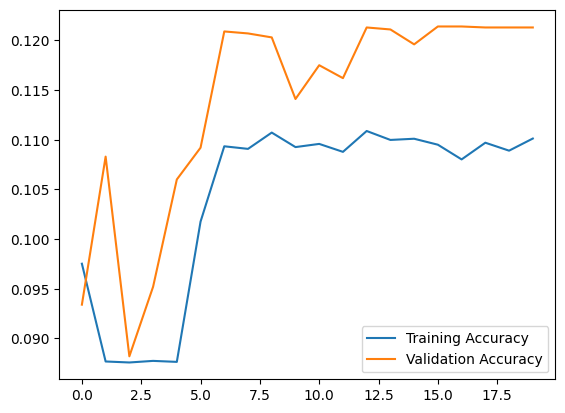

In [86]:
layers = [ 
    Dense(images_train.shape[1], 256),
    ReLU(),
    Dropout(0.5),
    Dense(256, 10)
]

NN = MyNeuralNetwork(layers)

NN.train(train_loader, validation_loader, '2SGD', 'SGD', epochs = epochs, batch_size=batch_size, learning_rate = 0.01)

In [87]:
predictions = []
for x in images_val:
    predictions.append(int(NN.predict(x)))
print(sklearn.metrics.classification_report(labels, predictions))

C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) + self.bias
C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\2787519319.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.maximum(0,input)


              precision    recall  f1-score   support

           0       0.11      0.76      0.19      1000
           1       0.00      0.00      0.00      1000
           2       0.00      0.00      0.00      1000
           3       0.00      0.00      0.00      1000
           4       0.00      0.00      0.00      1000
           5       0.00      0.00      0.00      1000
           6       0.00      0.00      0.00      1000
           7       0.00      0.00      0.00      1000
           8       0.00      0.00      0.00      1000
           9       0.15      0.43      0.22      1000

    accuracy                           0.12     10000
   macro avg       0.03      0.12      0.04     10000
weighted avg       0.03      0.12      0.04     10000



c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(avera

### 2.2.5 1 Hidden Layer with Adagrad ###

C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) + self.bias
C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:20: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  weights_gradient = np.matmul(gradient, self.input.T)


1/20, error=2.350337739789465, train accuracy=0.11154, validation accuracy=0.1334
2/20, error=2.3141577397894646, train accuracy=0.14774, validation accuracy=0.1653
3/20, error=2.2951577397894645, train accuracy=0.16674, validation accuracy=0.1693
4/20, error=2.2944377397894646, train accuracy=0.16748, validation accuracy=0.1615
5/20, error=2.2802777397894647, train accuracy=0.1816, validation accuracy=0.1923
6/20, error=2.2682777397894647, train accuracy=0.19354, validation accuracy=0.1995
7/20, error=2.2549777397894646, train accuracy=0.2068, validation accuracy=0.2129
8/20, error=2.2650977397894647, train accuracy=0.19682, validation accuracy=0.1823
9/20, error=2.2744977397894646, train accuracy=0.1874, validation accuracy=0.1799
10/20, error=2.2697777397894647, train accuracy=0.19208, validation accuracy=0.1933
11/20, error=2.2619177397894648, train accuracy=0.19992, validation accuracy=0.2183
12/20, error=2.2331777397894648, train accuracy=0.22868, validation accuracy=0.2352
13/20

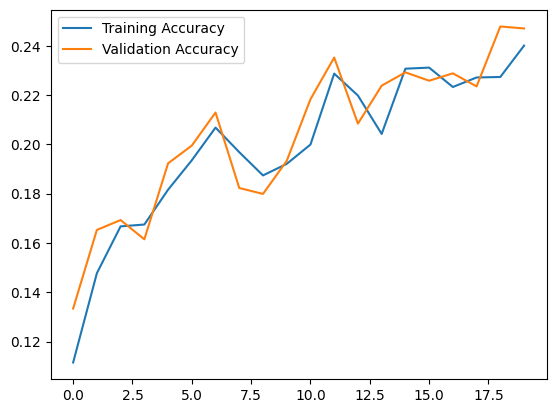

In [88]:
layers = [ 
    Dense(images_train.shape[1], 10)
]

NN = MyNeuralNetwork(layers)

NN.train(train_loader, validation_loader, '1Ada', 'Adagrad', epochs = 100, batch_size=batch_size, learning_rate = 0.1)

In [89]:
predictions = []
for x in images_val:
    predictions.append(int(NN.predict(x)))
print(sklearn.metrics.classification_report(labels, predictions))

C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) + self.bias


              precision    recall  f1-score   support

           0       0.27      0.21      0.24      1000
           1       0.27      0.24      0.25      1000
           2       0.18      0.17      0.18      1000
           3       0.20      0.16      0.18      1000
           4       0.23      0.22      0.23      1000
           5       0.24      0.22      0.23      1000
           6       0.30      0.38      0.34      1000
           7       0.24      0.25      0.24      1000
           8       0.26      0.32      0.29      1000
           9       0.27      0.30      0.28      1000

    accuracy                           0.25     10000
   macro avg       0.25      0.25      0.25     10000
weighted avg       0.25      0.25      0.25     10000



### 2.2.7 2 Hidden Layers with Adagrad ###

C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) + self.bias
C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\2787519319.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.maximum(0,input)
C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:20: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  weights_gradient = np.matmul(gradient, self.input.T)


1/20, error=2.3333577397894647, train accuracy=0.12856, validation accuracy=0.1276
2/20, error=2.3350977397894646, train accuracy=0.1268, validation accuracy=0.1369
3/20, error=2.334117739789465, train accuracy=0.12778, validation accuracy=0.1252
4/20, error=2.3384977397894646, train accuracy=0.1234, validation accuracy=0.1248
5/20, error=2.3388577397894648, train accuracy=0.12304, validation accuracy=0.132
6/20, error=2.340777739789465, train accuracy=0.12116, validation accuracy=0.1309
7/20, error=2.3379777397894648, train accuracy=0.1239, validation accuracy=0.1305
8/20, error=2.3391977397894648, train accuracy=0.12268, validation accuracy=0.1313
9/20, error=2.3385177397894648, train accuracy=0.12342, validation accuracy=0.134
10/20, error=2.3381777397894647, train accuracy=0.1237, validation accuracy=0.1279
11/20, error=2.337437739789465, train accuracy=0.12448, validation accuracy=0.1273
12/20, error=2.3367177397894645, train accuracy=0.12522, validation accuracy=0.133
13/20, erro

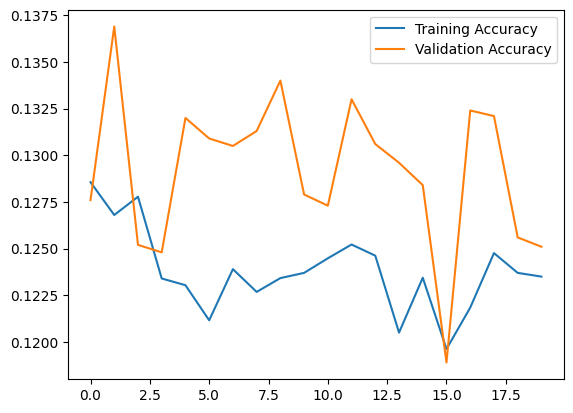

In [90]:
layers = [ 
    Dense(images_train.shape[1], 256),
    ReLU(),
    Dropout(0.5),
    Dense(256, 10)
]

NN = MyNeuralNetwork(layers)

NN.train(train_loader, validation_loader, '2Ada', 'Adagrad', epochs = epochs, batch_size=batch_size, learning_rate = 0.1)

In [91]:
predictions = []
for x in images_val:
    predictions.append(int(NN.predict(x)))
print(sklearn.metrics.classification_report(labels, predictions))

C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\3241388562.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) + self.bias
C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_10504\2787519319.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.maximum(0,input)


              precision    recall  f1-score   support

           0       0.32      0.14      0.19      1000
           1       0.14      0.01      0.02      1000
           2       0.18      0.01      0.02      1000
           3       0.15      0.04      0.06      1000
           4       0.14      0.07      0.10      1000
           5       0.18      0.03      0.05      1000
           6       0.10      0.85      0.19      1000
           7       0.15      0.04      0.06      1000
           8       0.17      0.01      0.01      1000
           9       0.15      0.02      0.04      1000

    accuracy                           0.12     10000
   macro avg       0.17      0.12      0.07     10000
weighted avg       0.17      0.12      0.07     10000



### Train function for Pytorch models ###

In [96]:
def train(model, name, criterion, optimizer, train_loader, images_val, labels, epochs = 20):
    loss_values = []
    train_acc = []
    val_acc = []
    best = 0
    for e in range(epochs):
        correct = 0
        for id_batch, (x_batch, y_batch) in enumerate(train_loader):
            y = y_batch.numpy()
            y_train = np.zeros([y.size, 10])
            y_train[np.arange(y.size), y] = 1
            y_train = torch.Tensor(y_train)

            output = model(x_batch)
            predictions = [int(np.argmax(x)) for x in output.detach().numpy()]
            correct += np.sum(predictions == y_batch.numpy())

            # Compute the loss (reconstruction error)
            loss = criterion(output, y_train)
            # Backpropagation and optimization
            optimizer.zero_grad()  # Clear previous gradients
            loss.backward()        # Backpropagate the error
            optimizer.step()       # Update the weights
        accuracy = float(correct) / len(train_loader.dataset)
        if accuracy > best:
            torch.save(model, 'models/'+ name +'.pth')
        predictions = [int(np.argmax(x)) for x in model(torch.Tensor(images_val)).detach().numpy()]
        val = float(np.sum(predictions == labels)) / len(labels)
        print(f"{e + 1}/{epochs}, error={loss.item():.4f}, train accuracy={accuracy}, validation accuracy={val}")
        loss_values.append(loss.item())
        train_acc.append(accuracy)
        val_acc.append(val)
    plt.plot(np.arange(epochs), train_acc, label='Training Accuracy')
    plt.plot(np.arange(epochs), val_acc, label='Validation Accuracy')
    plt.legend()
    plt.show()


### 2.2.2 1 Hidden Layer SGD Pytorch ###

1/20, error=2.3138, train accuracy=0.32402, validation accuracy=0.3494
2/20, error=2.0119, train accuracy=0.34404, validation accuracy=0.3363
3/20, error=2.3738, train accuracy=0.34532, validation accuracy=0.3152
4/20, error=2.2058, train accuracy=0.34862, validation accuracy=0.3239
5/20, error=1.9146, train accuracy=0.34984, validation accuracy=0.3195
6/20, error=2.2275, train accuracy=0.35222, validation accuracy=0.3491
7/20, error=1.7619, train accuracy=0.35516, validation accuracy=0.3393
8/20, error=1.6361, train accuracy=0.35362, validation accuracy=0.3346
9/20, error=1.4584, train accuracy=0.35338, validation accuracy=0.3245
10/20, error=1.9301, train accuracy=0.35626, validation accuracy=0.3388
11/20, error=1.6837, train accuracy=0.3545, validation accuracy=0.3423
12/20, error=1.7625, train accuracy=0.35606, validation accuracy=0.3148
13/20, error=2.1771, train accuracy=0.35452, validation accuracy=0.336
14/20, error=1.7362, train accuracy=0.3577, validation accuracy=0.3477
15/2

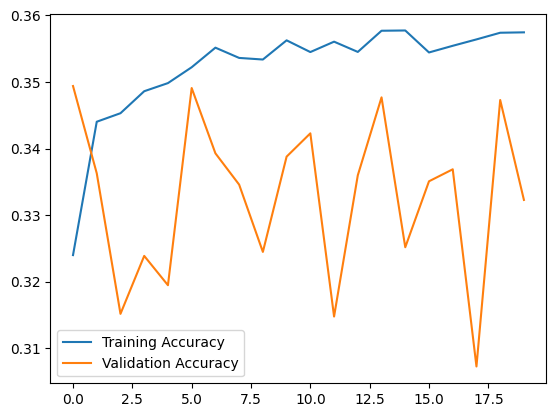

In [97]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(input_size, 10))
    def forward(self, x):
        return self.model.forward(x)

mlp = MLP(train_dataset[0][0].numpy().size)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(mlp.parameters(), lr = 0.01) 

train(mlp, 'torch1SGD', criterion, optimizer, train_loader, images_val, labels, epochs)

In [98]:
predictions = [int(np.argmax(x)) for x in mlp(torch.Tensor(images_val)).detach().numpy()]
print(sklearn.metrics.classification_report(labels, predictions))

              precision    recall  f1-score   support

           0       0.36      0.37      0.37      1000
           1       0.44      0.36      0.40      1000
           2       0.20      0.25      0.22      1000
           3       0.28      0.23      0.25      1000
           4       0.34      0.21      0.26      1000
           5       0.23      0.15      0.18      1000
           6       0.35      0.51      0.41      1000
           7       0.43      0.42      0.42      1000
           8       0.32      0.45      0.37      1000
           9       0.41      0.38      0.39      1000

    accuracy                           0.33     10000
   macro avg       0.33      0.33      0.33     10000
weighted avg       0.33      0.33      0.33     10000



### 2.2.4 2 Hidden Layers SGD Pytorch ###

1/20, error=1.2824, train accuracy=0.3616, validation accuracy=0.4042
2/20, error=1.5276, train accuracy=0.41182, validation accuracy=0.4232
3/20, error=1.5557, train accuracy=0.42896, validation accuracy=0.4392
4/20, error=1.6755, train accuracy=0.44392, validation accuracy=0.4472
5/20, error=1.6648, train accuracy=0.44994, validation accuracy=0.4503
6/20, error=1.7515, train accuracy=0.45692, validation accuracy=0.4505
7/20, error=1.6025, train accuracy=0.46124, validation accuracy=0.456
8/20, error=1.5418, train accuracy=0.46232, validation accuracy=0.4522
9/20, error=0.9391, train accuracy=0.469, validation accuracy=0.459
10/20, error=1.6260, train accuracy=0.47338, validation accuracy=0.4617
11/20, error=1.5118, train accuracy=0.47684, validation accuracy=0.4701
12/20, error=1.1428, train accuracy=0.47916, validation accuracy=0.4723
13/20, error=1.9191, train accuracy=0.48184, validation accuracy=0.4696
14/20, error=1.1745, train accuracy=0.48238, validation accuracy=0.4732
15/20,

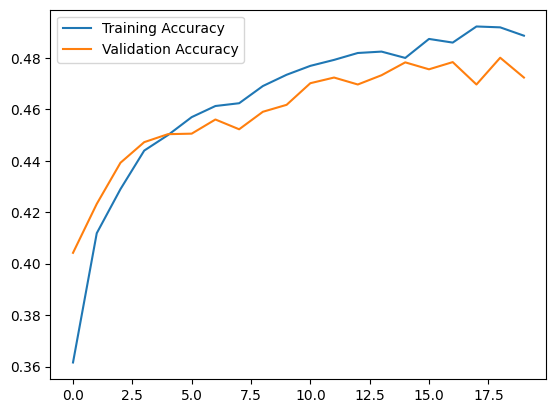

In [99]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 10))
    def forward(self, x):
        return self.model.forward(x)

mlp = MLP(train_dataset[0][0].numpy().size)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(mlp.parameters(), lr = 0.01) 

train(mlp, 'torch2SGD', criterion, optimizer, train_loader, images_val, labels, epochs)

In [100]:
predictions = [int(np.argmax(x)) for x in mlp(torch.Tensor(images_val)).detach().numpy()]
print(sklearn.metrics.classification_report(labels, predictions))

              precision    recall  f1-score   support

           0       0.56      0.46      0.51      1000
           1       0.57      0.55      0.56      1000
           2       0.37      0.32      0.35      1000
           3       0.33      0.27      0.29      1000
           4       0.40      0.50      0.44      1000
           5       0.39      0.38      0.38      1000
           6       0.52      0.56      0.54      1000
           7       0.58      0.50      0.54      1000
           8       0.51      0.68      0.59      1000
           9       0.51      0.53      0.52      1000

    accuracy                           0.47     10000
   macro avg       0.47      0.47      0.47     10000
weighted avg       0.47      0.47      0.47     10000



### 2.2.6 1 Hidden Layer Adagrad Pytorch ###

1/20, error=3.3982, train accuracy=0.2766, validation accuracy=0.2791
2/20, error=2.0711, train accuracy=0.29174, validation accuracy=0.2853
3/20, error=3.5987, train accuracy=0.30262, validation accuracy=0.2921
4/20, error=2.3338, train accuracy=0.31564, validation accuracy=0.3063
5/20, error=1.7713, train accuracy=0.32222, validation accuracy=0.2907
6/20, error=2.3114, train accuracy=0.32892, validation accuracy=0.2946
7/20, error=2.2366, train accuracy=0.33214, validation accuracy=0.2967
8/20, error=1.2314, train accuracy=0.33624, validation accuracy=0.3342
9/20, error=2.5568, train accuracy=0.3367, validation accuracy=0.3436
10/20, error=1.6139, train accuracy=0.34294, validation accuracy=0.321
11/20, error=1.6431, train accuracy=0.3435, validation accuracy=0.3267
12/20, error=1.7528, train accuracy=0.34782, validation accuracy=0.34
13/20, error=2.3265, train accuracy=0.34702, validation accuracy=0.298
14/20, error=1.8750, train accuracy=0.35224, validation accuracy=0.3523
15/20, e

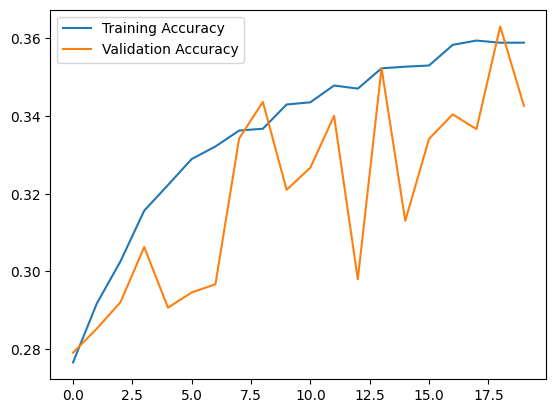

In [104]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(input_size, 10))
    def forward(self, x):
        return self.model.forward(x)

mlp = MLP(train_dataset[0][0].numpy().size)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adagrad(mlp.parameters(), lr = 0.1) 

train(mlp, 'torchAda', criterion, optimizer, train_loader, images_val, labels, epochs)

In [105]:
predictions = [int(np.argmax(x)) for x in mlp(torch.Tensor(images_val)).detach().numpy()]
print(sklearn.metrics.classification_report(labels, predictions))

              precision    recall  f1-score   support

           0       0.41      0.48      0.44      1000
           1       0.50      0.28      0.36      1000
           2       0.22      0.19      0.20      1000
           3       0.18      0.20      0.19      1000
           4       0.33      0.26      0.29      1000
           5       0.29      0.21      0.24      1000
           6       0.33      0.57      0.42      1000
           7       0.36      0.45      0.40      1000
           8       0.49      0.35      0.41      1000
           9       0.40      0.43      0.42      1000

    accuracy                           0.34     10000
   macro avg       0.35      0.34      0.34     10000
weighted avg       0.35      0.34      0.34     10000



### 2.2.8 2 Hidden Layers Adagrad Pytorch ###

1/20, error=2.6157, train accuracy=0.19432, validation accuracy=0.2052
2/20, error=3.7898, train accuracy=0.21386, validation accuracy=0.2321
3/20, error=2.9215, train accuracy=0.2311, validation accuracy=0.2326
4/20, error=1.9938, train accuracy=0.24922, validation accuracy=0.2607
5/20, error=2.2863, train accuracy=0.26042, validation accuracy=0.2587
6/20, error=2.4555, train accuracy=0.27536, validation accuracy=0.2721
7/20, error=2.5135, train accuracy=0.28694, validation accuracy=0.2738
8/20, error=1.9528, train accuracy=0.29166, validation accuracy=0.3062
9/20, error=2.4581, train accuracy=0.30892, validation accuracy=0.3092
10/20, error=1.7754, train accuracy=0.3175, validation accuracy=0.3278
11/20, error=2.0723, train accuracy=0.3265, validation accuracy=0.3207
12/20, error=1.6126, train accuracy=0.32914, validation accuracy=0.3288
13/20, error=1.4775, train accuracy=0.33546, validation accuracy=0.3424
14/20, error=1.6451, train accuracy=0.34368, validation accuracy=0.3411
15/2

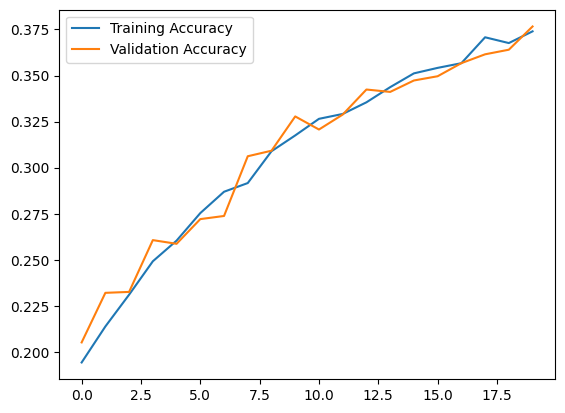

In [106]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 10))
    def forward(self, x):
        return self.model.forward(x)

mlp = MLP(train_dataset[0][0].numpy().size)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adagrad(mlp.parameters(), lr = 0.1) 

train(mlp, '2torchAda', criterion, optimizer, train_loader, images_val, labels, epochs)

In [107]:
predictions = [int(np.argmax(x)) for x in mlp(torch.Tensor(images_val)).detach().numpy()]
print(sklearn.metrics.classification_report(labels, predictions))

              precision    recall  f1-score   support

           0       0.46      0.38      0.41      1000
           1       0.50      0.41      0.45      1000
           2       0.25      0.18      0.21      1000
           3       0.29      0.06      0.10      1000
           4       0.31      0.40      0.35      1000
           5       0.34      0.37      0.35      1000
           6       0.32      0.55      0.40      1000
           7       0.42      0.43      0.43      1000
           8       0.46      0.55      0.50      1000
           9       0.38      0.43      0.40      1000

    accuracy                           0.37     10000
   macro avg       0.37      0.37      0.36     10000
weighted avg       0.37      0.37      0.36     10000



### Data Preprocessing ###

In [4]:
mean = (0.49139968, 0.48215827 ,0.44653124)
std = (0.24703233, 0.24348505, 0.26158768)

transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.Normalize(mean, std),
])

transform_val= transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

test_size = 10000
batch_size = 32

train_dataset =  datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
validation_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_val)

# Create train and validation batch for training
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, shuffle=True, batch_size=batch_size, num_workers=2)
validation_loader = torch.utils.data.DataLoader(dataset=validation_dataset, shuffle=True, batch_size=test_size)

Files already downloaded and verified
Files already downloaded and verified


In [5]:
images_train, labels_train = next(iter(train_loader))
images_val, labels_val = next(iter(validation_loader))
labels = labels_val.numpy()

### 2.4.1 5 Hidden Layers Pytorch ###

1/10, error=1.4142, train accuracy=0.35208, validation accuracy=0.4126
2/10, error=1.4521, train accuracy=0.41598, validation accuracy=0.4304
3/10, error=1.2268, train accuracy=0.43912, validation accuracy=0.4494
4/10, error=1.8614, train accuracy=0.45558, validation accuracy=0.4564
5/10, error=1.1353, train accuracy=0.46906, validation accuracy=0.4593
6/10, error=1.3249, train accuracy=0.475, validation accuracy=0.4804
7/10, error=1.7979, train accuracy=0.48388, validation accuracy=0.478
8/10, error=1.6100, train accuracy=0.49332, validation accuracy=0.4807
9/10, error=1.0274, train accuracy=0.49758, validation accuracy=0.4932
10/10, error=1.6077, train accuracy=0.5005, validation accuracy=0.4855


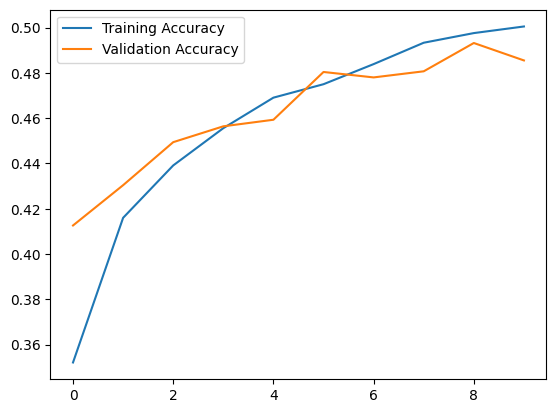

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()

        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_size, 2048),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(2048, 1024),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(256,10))
    def forward(self, x):
        return self.model.forward(x)

mlp = MLP(train_dataset[0][0].numpy().size)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp.parameters()) 

epochs = 10

train(mlp, 'Linear5', criterion, optimizer, train_loader, images_val, labels, epochs)


In [ ]:
predictions = [int(np.argmax(x)) for x in mlp(torch.Tensor(images_val)).detach().numpy()]
print(sklearn.metrics.classification_report(labels, predictions))

              precision    recall  f1-score   support

           0       0.44      0.48      0.46      1000
           1       0.53      0.57      0.55      1000
           2       0.38      0.33      0.35      1000
           3       0.28      0.35      0.31      1000
           4       0.33      0.33      0.33      1000
           5       0.45      0.26      0.33      1000
           6       0.41      0.52      0.46      1000
           7       0.57      0.48      0.52      1000
           8       0.49      0.54      0.51      1000
           9       0.50      0.45      0.48      1000

    accuracy                           0.43     10000
   macro avg       0.44      0.43      0.43     10000
weighted avg       0.44      0.43      0.43     10000



### 2.4.2 Convolutional Pytorch ###

1/10, error=1.3828, train accuracy=0.4788, validation accuracy=0.591
2/10, error=1.9848, train accuracy=0.6146, validation accuracy=0.599
3/10, error=1.1853, train accuracy=0.66106, validation accuracy=0.6932
4/10, error=0.7276, train accuracy=0.70492, validation accuracy=0.7151
5/10, error=0.8023, train accuracy=0.74278, validation accuracy=0.7426
6/10, error=0.6320, train accuracy=0.75562, validation accuracy=0.7577
7/10, error=0.8818, train accuracy=0.7516, validation accuracy=0.764
8/10, error=0.8228, train accuracy=0.7744, validation accuracy=0.7767
9/10, error=0.3260, train accuracy=0.80292, validation accuracy=0.7736
10/10, error=0.7720, train accuracy=0.78736, validation accuracy=0.7704


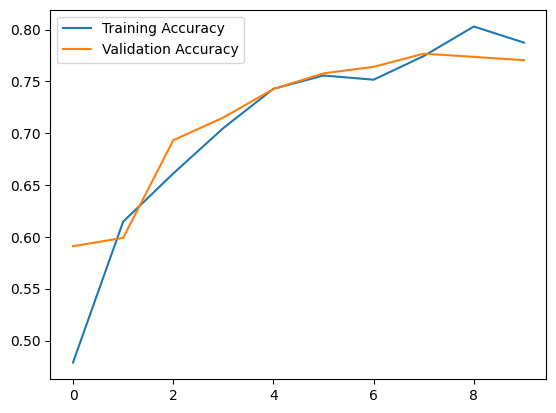

In [ ]:
class Conv(nn.Module):
    def __init__(self, input_size):
        super(Conv, self).__init__()

        self.model = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.Conv2d(128, 128, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2, 2), # output: 128 x 16 x 16
            nn.Dropout2d(0.25),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(256),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(256),
            nn.MaxPool2d(2, 2), # output: 256 x 8 x 8
            nn.Dropout2d(0.25),

            nn.Flatten(),

            nn.Linear(256*8*8, 1024),
            nn.ReLU(),
            nn.BatchNorm1d(1024),
            nn.Linear(1024, 512),
            nn.ReLU(), 
            nn.BatchNorm1d(512),
            nn.Dropout(0.5),
            nn.Linear(512, 10))
    def forward(self, x):
        return self.model.forward(x)

conv = Conv(train_dataset[0][0].numpy().shape[0])
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(conv.parameters()) 

epochs = 10

train(conv, 'Conv', criterion, optimizer, train_loader, images_val, labels, epochs)

In [ ]:
predictions = [int(np.argmax(x)) for x in conv(torch.Tensor(images_val)).detach().numpy()]
print(sklearn.metrics.classification_report(labels, predictions))

              precision    recall  f1-score   support

           0       0.78      0.80      0.79      1000
           1       0.82      0.91      0.86      1000
           2       0.67      0.72      0.69      1000
           3       0.58      0.61      0.60      1000
           4       0.74      0.74      0.74      1000
           5       0.75      0.57      0.65      1000
           6       0.82      0.82      0.82      1000
           7       0.82      0.81      0.82      1000
           8       0.85      0.85      0.85      1000
           9       0.82      0.80      0.81      1000

    accuracy                           0.76     10000
   macro avg       0.77      0.76      0.76     10000
weighted avg       0.77      0.76      0.76     10000



### 2.6 Examples of correctly and incorrectly predicted images ###

In [8]:
classes = ('airplane', 
           'automobile', 
           'bird',
           'cat',
           'deer',
           'dog', 
           'frog', 
           'horse', 
           'ship',
           'truck')

In [13]:
correct_preds_by_class = {i: [] for i in range(10)}
incorrect_preds_by_class = {i: [] for i in range(10)}

for images, labels in validation_loader:
        outputs = conv(images) 
        _, predicted = torch.max(outputs, 1) 
        
        for i in range(len(labels)):
            true_label = labels[i].item()
            pred_label = predicted[i].item()
            
            if pred_label == true_label and len(correct_preds_by_class[true_label]) < 10:
                correct_preds_by_class[true_label].append((images[i], true_label, pred_label))
            elif pred_label != true_label and len(incorrect_preds_by_class[true_label]) < 10:
                incorrect_preds_by_class[true_label].append((images[i], true_label, pred_label))

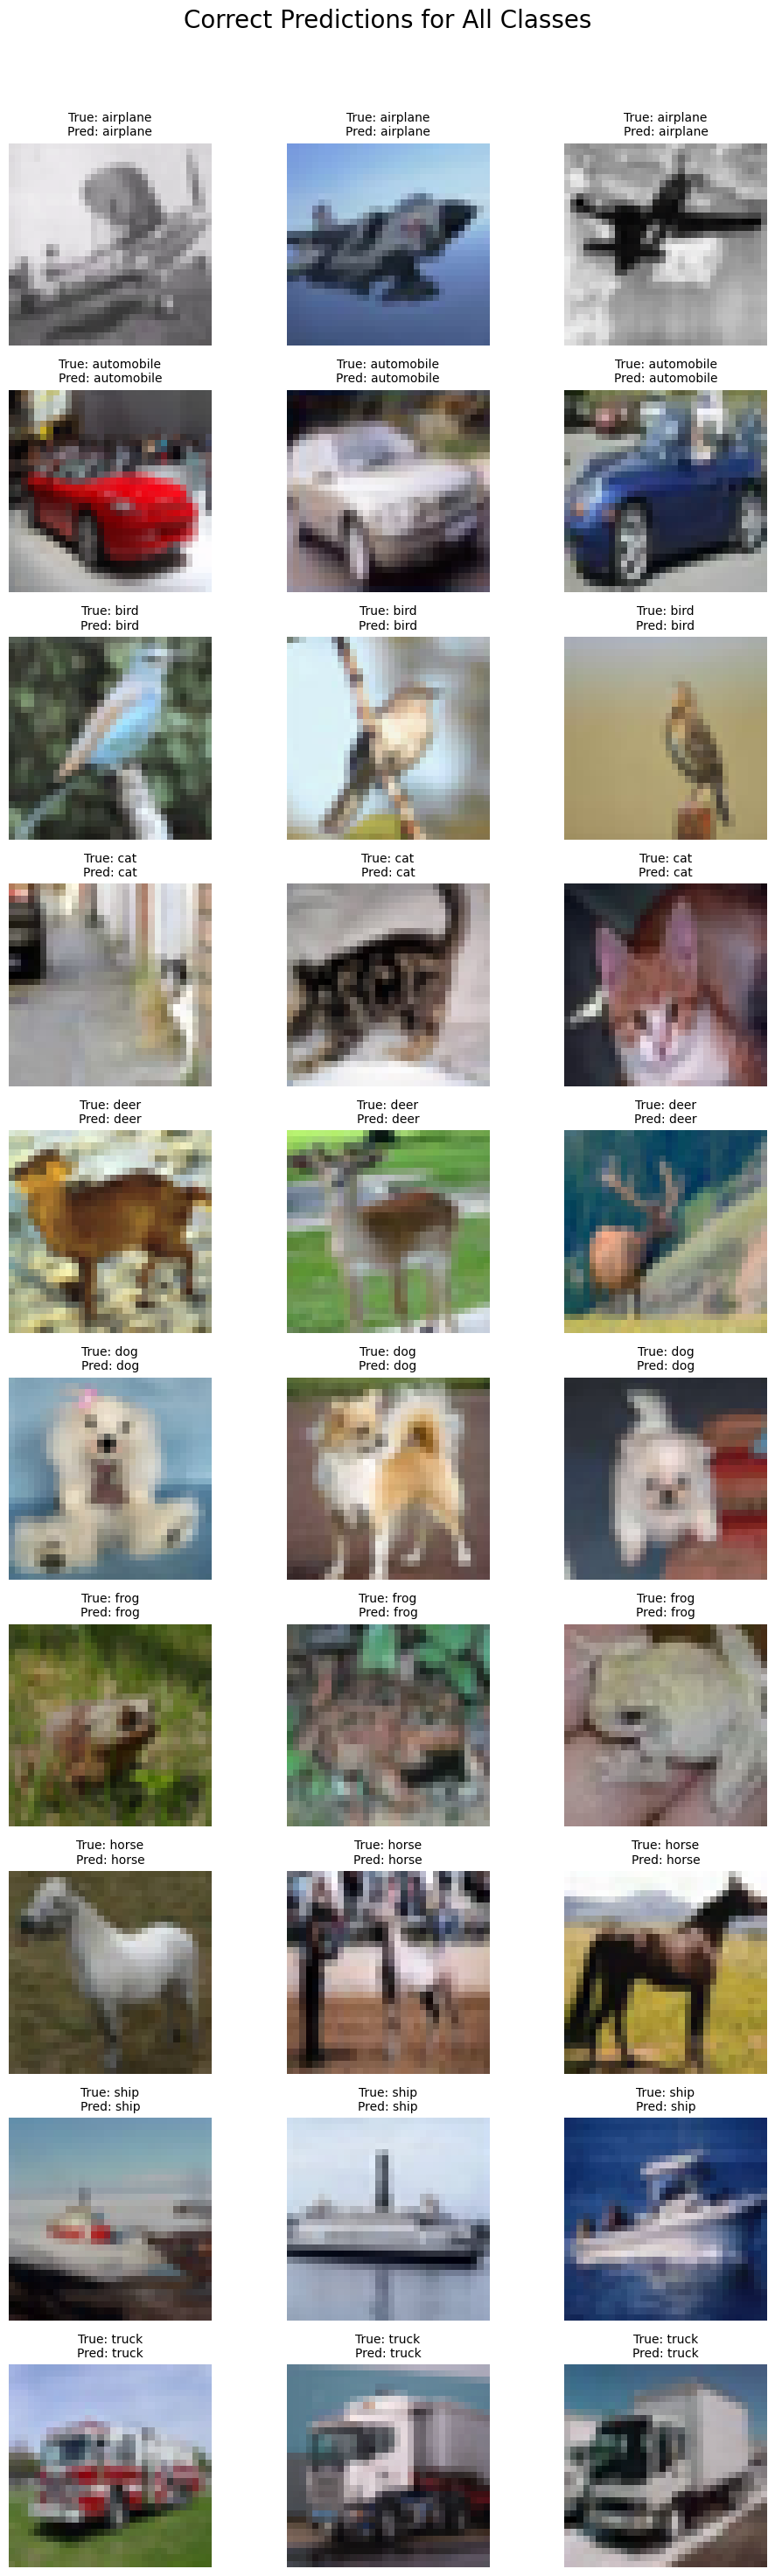

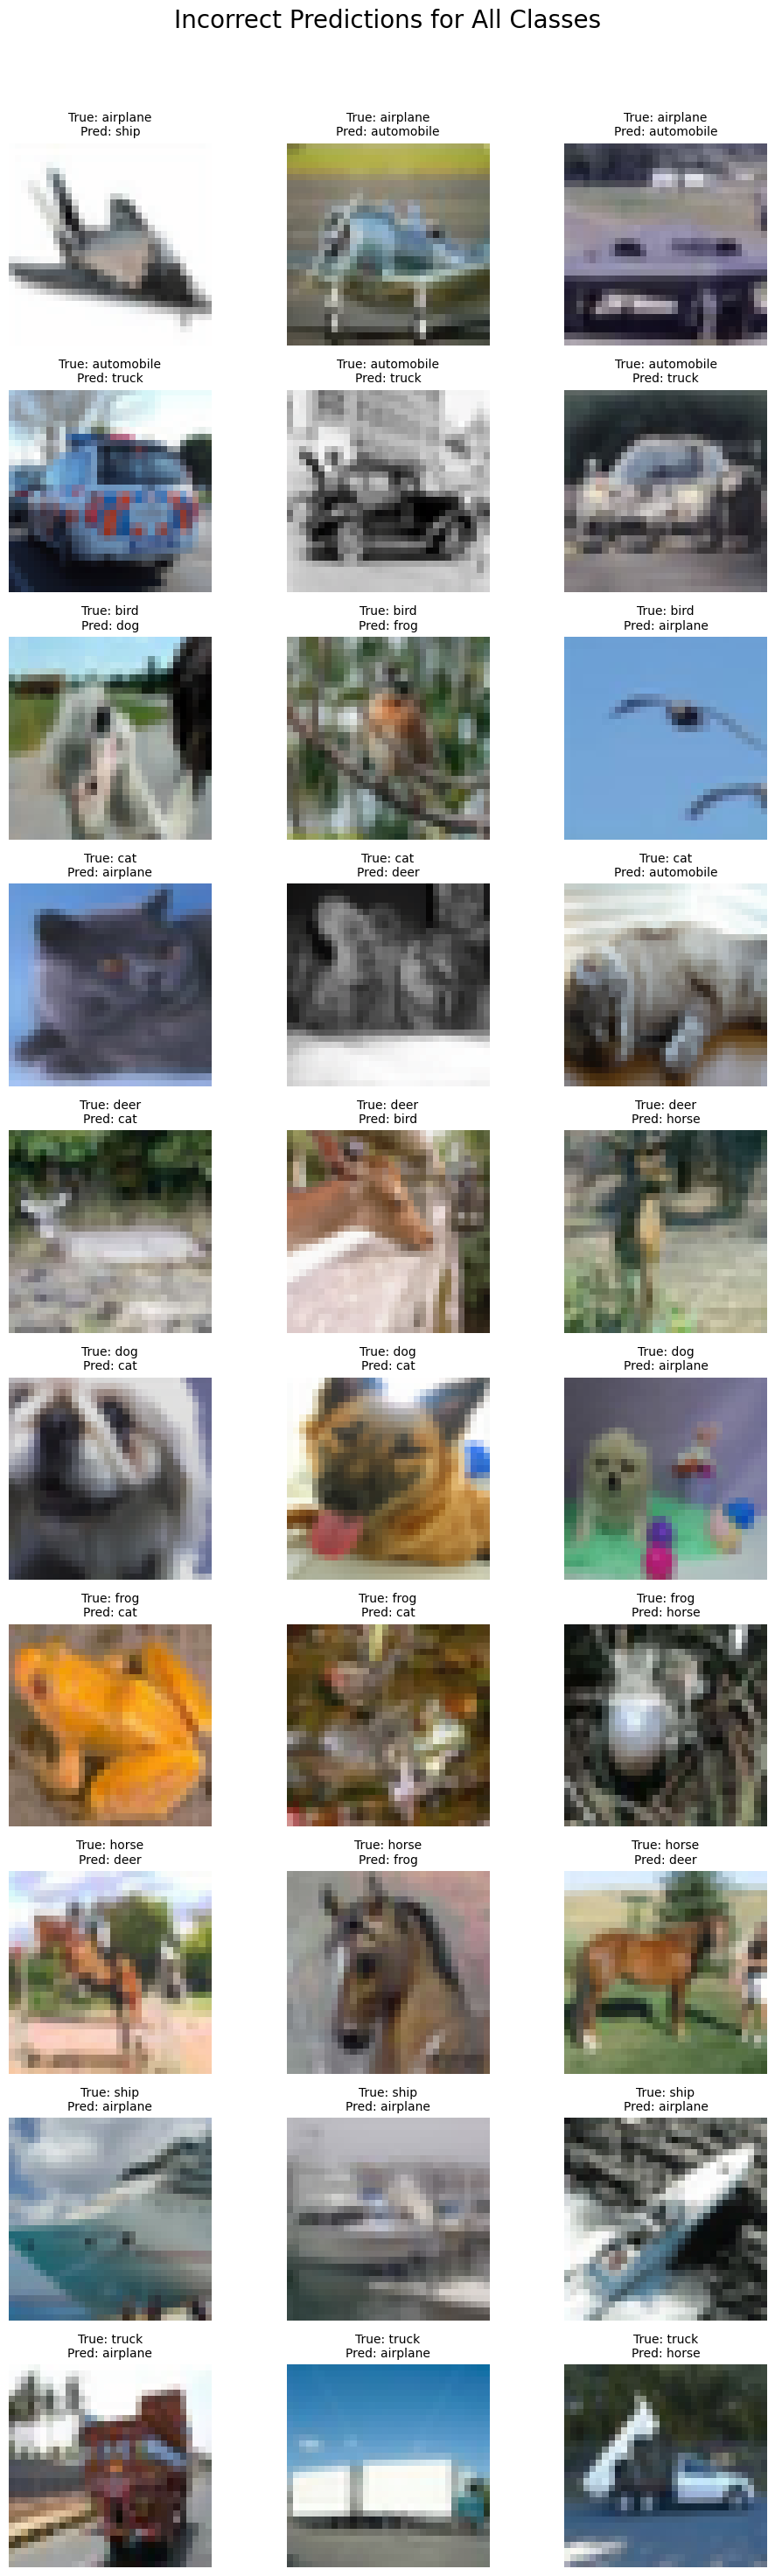

In [14]:
def plot_images_grid(images_dict, title):
    fig, axes = plt.subplots(10, 3, figsize=(10, 10 * 3))
    fig.suptitle(title, fontsize=20)
    for class_idx in range(10):
        images_list = images_dict[class_idx]
        for idx in range(3):
            ax = axes[class_idx, idx]
            ax.axis('off')
            if idx < len(images_list):
                img, true_label, pred_label = images_list[idx]
                ax.imshow(((img.permute(1, 2, 0)).numpy()*std+mean).clip(0,1))
                ax.set_title(f'True: {classes[true_label]}\nPred: {classes[pred_label]}', fontsize=10)
            else:
                ax.set_visible(False) 

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

plot_images_grid(correct_preds_by_class, 'Correct Predictions for All Classes')
plot_images_grid(incorrect_preds_by_class, 'Incorrect Predictions for All Classes')